In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [11]:
df = pd.read_csv('/content/student_marks_prediction_dataset.csv')
print(df.head())
print(df.describe())
print(df.isnull().sum())

   Study_Hours  Attendance  Marks
0            7          53     49
1            4          51     29
2            8          55     55
3            5          91     50
4            7          53     51
       Study_Hours  Attendance      Marks
count    50.000000   50.000000  50.000000
mean      5.200000   72.660000  44.240000
std       2.490799   14.796042  14.772506
min       1.000000   50.000000  14.000000
25%       3.000000   59.250000  33.000000
50%       5.000000   73.000000  47.500000
75%       7.000000   84.000000  54.750000
max       9.000000  100.000000  74.000000
Study_Hours    0
Attendance     0
Marks          0
dtype: int64


             Study_Hours  Attendance     Marks
Study_Hours     1.000000   -0.044079  0.915488
Attendance     -0.044079    1.000000  0.238659
Marks           0.915488    0.238659  1.000000


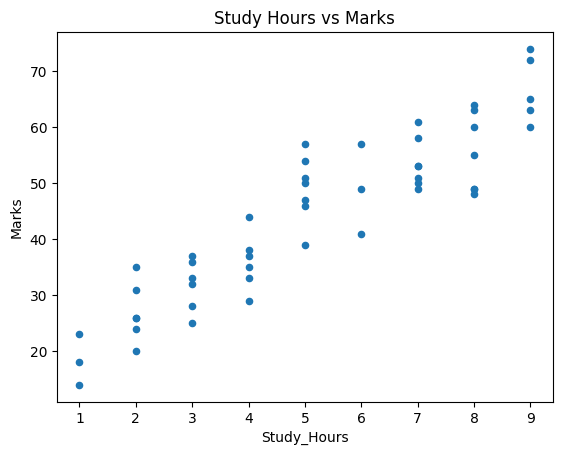

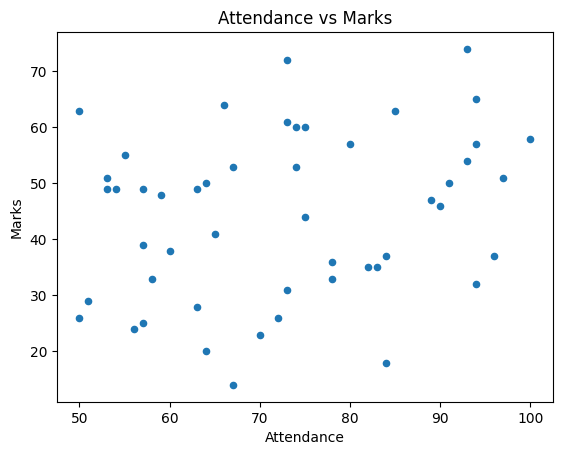

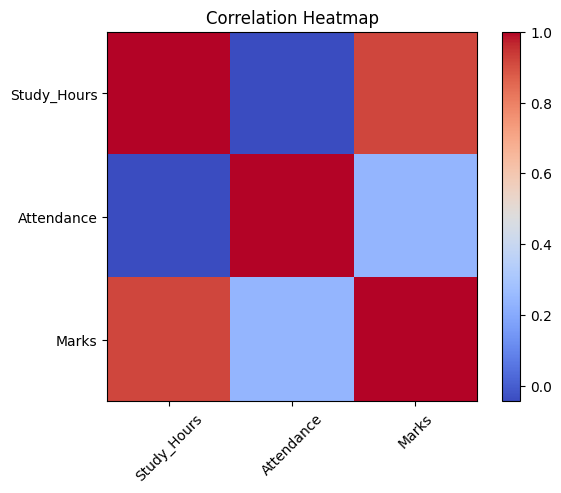

In [12]:
print(df.corr())

df.plot(x='Study_Hours', y='Marks', kind='scatter', title='Study Hours vs Marks')
plt.show()

df.plot(x='Attendance', y='Marks', kind='scatter', title='Attendance vs Marks')
plt.show()

plt.imshow(df.corr(), cmap='coolwarm')
plt.colorbar()
plt.xticks(range(3), df.columns, rotation=45)
plt.yticks(range(3), df.columns)
plt.title('Correlation Heatmap')
plt.show()

In [13]:
s = df.head(6)
X = np.column_stack((np.ones(6), s['Study_Hours'], s['Attendance']))
y = s['Marks'].values

b = np.linalg.solve(X.T @ X, X.T @ y)

print("X:", X)
print("XTX:", X.T @ X)
print("XTy:", X.T @ y)
print("Coefficients:", b)
print("Prediction:", X[0] @ b)
print("Residual:", y[0] - X[0] @ b)

X: [[ 1.  7. 53.]
 [ 1.  4. 51.]
 [ 1.  8. 55.]
 [ 1.  5. 91.]
 [ 1.  7. 53.]
 [ 1.  3. 78.]]
XTX: [[6.0000e+00 3.4000e+01 3.8100e+02]
 [3.4000e+01 2.1200e+02 2.0750e+03]
 [3.8100e+02 2.0750e+03 2.5609e+04]]
XTy: [  267.  1605. 16928.]
Coefficients: [-13.77221775   6.3022107    0.35527072]
Prediction: 49.17260507787498
Residual: -0.1726050778749766


In [14]:
X = df[['Study_Hours', 'Attendance']]
y = df['Marks']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Single regression
m1 = LinearRegression()
m1.fit(X_train[['Study_Hours']], y_train)
p1 = m1.predict(X_test[['Study_Hours']])

# Multiple regression
m2 = LinearRegression()
m2.fit(X_train, y_train)
p2 = m2.predict(X_test)

print("Single R2:", r2_score(y_test, p1))
print("Multiple R2:", r2_score(y_test, p2))
print("MAE:", mean_absolute_error(y_test, p2))
print("MSE:", mean_squared_error(y_test, p2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, p2)))

r2 = r2_score(y_test, p2)
n, p = len(y_test), 2
print("Adjusted R2:", 1 - (1-r2)*(n-1)/(n-p-1))
print("Intercept:", m2.intercept_)
print("Coefficients:", m2.coef_)

Single R2: 0.5996564850045911
Multiple R2: 0.7980560661136888
MAE: 5.542065551422866
MSE: 37.65244647310272
RMSE: 6.136158934798114
Adjusted R2: 0.7403577992890285
Intercept: -2.036854782785049
Coefficients: [5.46351418 0.23205904]


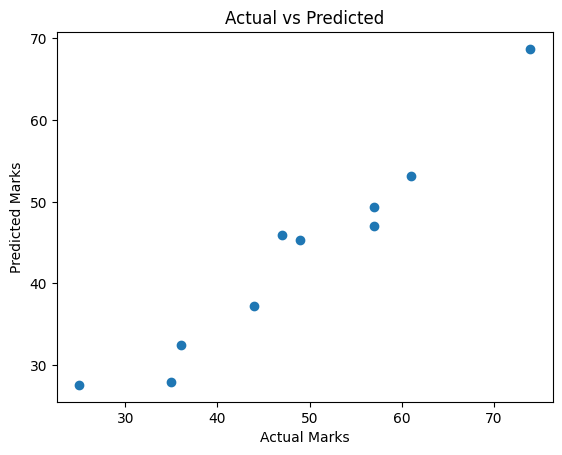

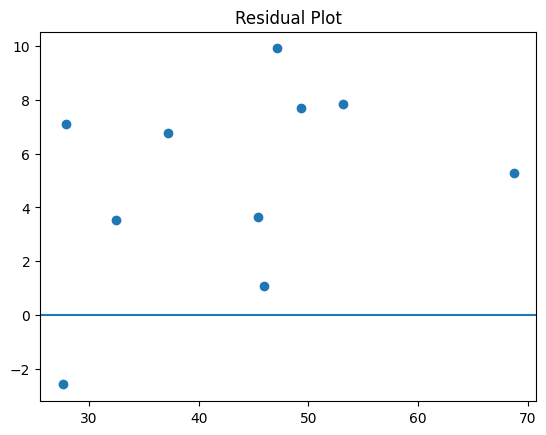

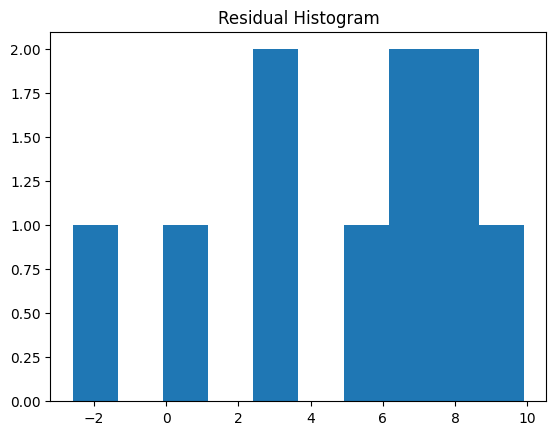

In [15]:
residual = y_test - p2

plt.scatter(y_test, p2)
plt.xlabel('Actual Marks')
plt.ylabel('Predicted Marks')
plt.title('Actual vs Predicted')
plt.show()

plt.scatter(p2, residual)
plt.axhline(0)
plt.title('Residual Plot')
plt.show()

plt.hist(residual)
plt.title('Residual Histogram')
plt.show()

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

for i in range(2):
    print(X.columns[i], "VIF:", variance_inflation_factor(X.values, i))

new = pd.DataFrame({'Study_Hours': [7], 'Attendance': [85]})
print("Predicted Marks:", m2.predict(new)[0])

Study_Hours VIF: 1.001946749200194
Attendance VIF: 1.001946749200194
Predicted Marks: 55.93276313002513
